# 09 · Test 标签与模型预测分布及 MAE–RMSE 误差分析

本 notebook 重新设计 08 中实验 A 的分布图，目的是更直接地展示：**HLR 系模型的大部分预测非常高，而直接预测回忆率的树模型输出更保守。**

第一张图沿用 EDA 的 20 个等宽区间，分别画出 Test 标签、HLR 和 RF-p 的棒形直方图，避免多条阶梯线互相遮挡。第二张图比较所有系列中 `p ≥ 0.95` 的记录占比，用一个数字概括高位集中的程度。N-HLR 和 LGBM-p 保留在汇总表和第二张图中。

本 notebook 不重新训练模型；已有统一比较缓存时直接读取。


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import display

from experiment_pipeline import Pipeline

run = Pipeline()
globals().update(run.comparison())

REPORTS_DIR = Path('reports')
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
SMALL_MULTIPLES_PATH = REPORTS_DIR / 's09_prediction_distribution_bars.png'
HIGH_SHARE_PATH = REPORTS_DIR / 's09_high_prediction_share.png'

distribution_series = {
    'p_target (true)': np.asarray(test_true_p, dtype=np.float64),
    'HLR': np.asarray(test_predictions['HLR'][0], dtype=np.float64),
    'N-HLR': np.asarray(test_predictions['N-HLR'][0], dtype=np.float64),
    'RF-p': np.asarray(test_predictions['RF-p (E2)'][0], dtype=np.float64),
    'LGBM-p': np.asarray(test_predictions['LGBM-p (E4)'][0], dtype=np.float64),
}
n_test_distribution = len(distribution_series['p_target (true)'])
assert all(len(values) == n_test_distribution for values in distribution_series.values())
assert all(np.isfinite(values).all() for values in distribution_series.values())
assert all(np.all((MIN_P <= values) & (values <= MAX_P))
           for values in distribution_series.values())
print(f'Test rows: {n_test_distribution:,}')


原始文件： D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
前 5 行：


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。
已复用与当前原始数据、切分一致的特征缓存。
缓存：D:\fujing123\Projects\Data-Analytic\HLR\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
基础特征： ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train 词项数：18,353；Validation 未见词项行数：1,150；Test 未见词项行数：560
Reused Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955


Loaded comparison results: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\comparison-c81f1ea0ab3c1d8d.joblib
Test rows: 1,285,415


## 9.1 分布统计

表格保留均值、标准差、分位数和边界占比。图形用于快速传达主要模式，精确比较仍以表格为准。


In [2]:
distribution_rows = []
for name, values in distribution_series.items():
    p10, p50, p90 = np.quantile(values, [0.10, 0.50, 0.90])
    distribution_rows.append({
        'series': name,
        'n_test': len(values),
        'mean': float(values.mean()),
        'std': float(values.std()),
        'P10': float(p10),
        'P50': float(p50),
        'P90': float(p90),
        'share_ge_0.95': float(np.mean(values >= 0.95)),
        'share_at_MIN_P': float(np.mean(values == MIN_P)),
        'share_at_MAX_P': float(np.mean(values == MAX_P)),
    })
distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.round(6))


,series,n_test,mean,std,P10,P50,P90,share_ge_0.95,share_at_MIN_P,share_at_MAX_P
0,p_target (true),1285415,0.895429,0.271137,0.500000,0.999900,0.999900,0.836041,0.070233,0.836030
1,HLR,1285415,0.962835,0.091981,0.903317,0.995612,0.999900,0.829599,0.000000,0.345267
2,N-HLR,1285415,0.976572,0.061257,0.941167,0.997467,0.999900,0.886834,0.000000,0.366044
3,RF-p,1285415,0.894972,0.044565,0.855217,0.902198,0.934825,0.021230,0.000000,0.000010
4,LGBM-p,1285415,0.894965,0.044095,0.855804,0.902438,0.935212,0.017517,0.000000,0.000019


## 9.2 与 EDA 对照的 20-bin 棒形直方图

三张图使用相同的 `[0,1]` 横轴和 20 个等宽区间。每根柱表示该系列落入相应区间的 Test 行占比。为了让每个分布的形状都清楚可见，三个面板分别调整纵轴范围，因此**不应根据柱子的绝对高度跨面板比较占比**；跨系列的精确占比见上一张表和下一张图。


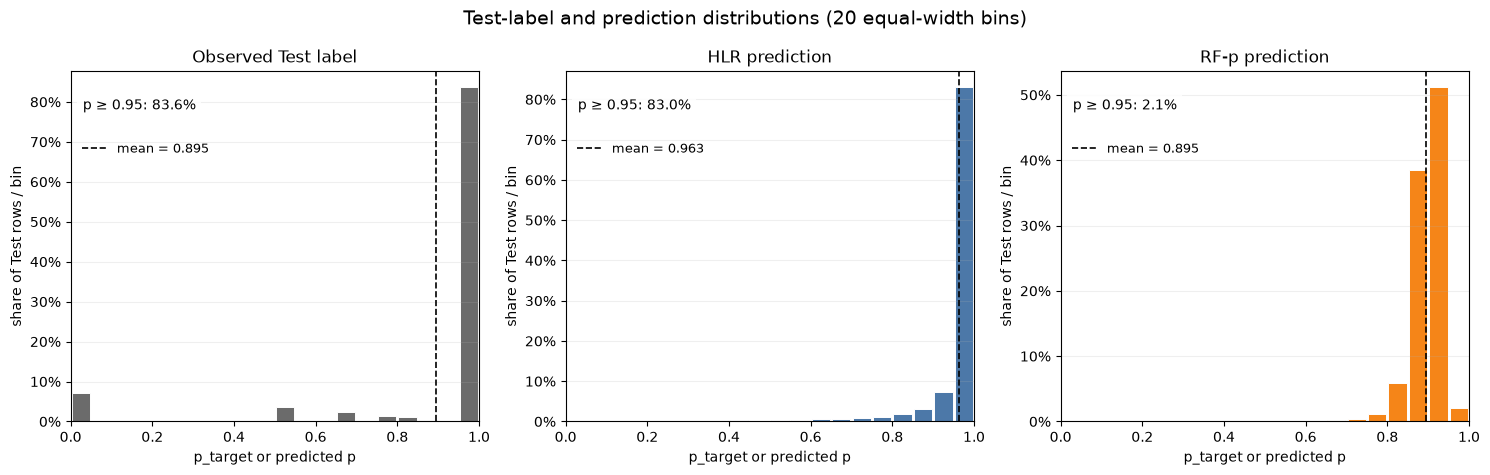

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_prediction_distribution_bars.png


In [3]:
histogram_names = ['p_target (true)', 'HLR', 'RF-p']
histogram_titles = {
    'p_target (true)': 'Observed Test label',
    'HLR': 'HLR prediction',
    'RF-p': 'RF-p prediction',
}
histogram_colors = {
    'p_target (true)': '#6B6B6B',
    'HLR': '#4C78A8',
    'RF-p': '#F58518',
}
histogram_edges = np.linspace(0.0, 1.0, 21)
histogram_centers = (histogram_edges[:-1] + histogram_edges[1:]) / 2
histogram_width = 0.9 * np.diff(histogram_edges)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
for ax, name in zip(axes, histogram_names):
    values = distribution_series[name]
    masses = np.histogram(values, bins=histogram_edges)[0] / len(values)
    ax.bar(
        histogram_centers, masses, width=histogram_width,
        color=histogram_colors[name], edgecolor='white', linewidth=0.7,
    )
    mean_value = float(values.mean())
    share_high = float(np.mean(values >= 0.95))
    ax.axvline(
        mean_value, color='black', linestyle='--', linewidth=1.2,
        label=f'mean = {mean_value:.3f}',
    )
    ax.text(
        0.03, 0.92, f'p ≥ 0.95: {share_high:.1%}',
        transform=ax.transAxes, ha='left', va='top', fontsize=10,
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85},
    )
    ax.set(
        title=histogram_titles[name], xlim=(0, 1),
        xlabel='p_target or predicted p', ylabel='share of Test rows / bin',
    )
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
    ax.grid(axis='y', alpha=0.2)
    ax.legend(loc='upper left', bbox_to_anchor=(0, 0.83), frameon=False, fontsize=9)
fig.suptitle(
    'Test-label and prediction distributions (20 equal-width bins)',
    fontsize=14,
)
fig.tight_layout()
fig.savefig(SMALL_MULTIPLES_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {SMALL_MULTIPLES_PATH.resolve()}')


## 9.3 极高预测占比

下面直接比较每个系列中 `p ≥ 0.95` 的行占比。该图不替代完整分布，而是将“模型是否经常给出极高回忆率”这一观点压缩成一个容易比较的量。


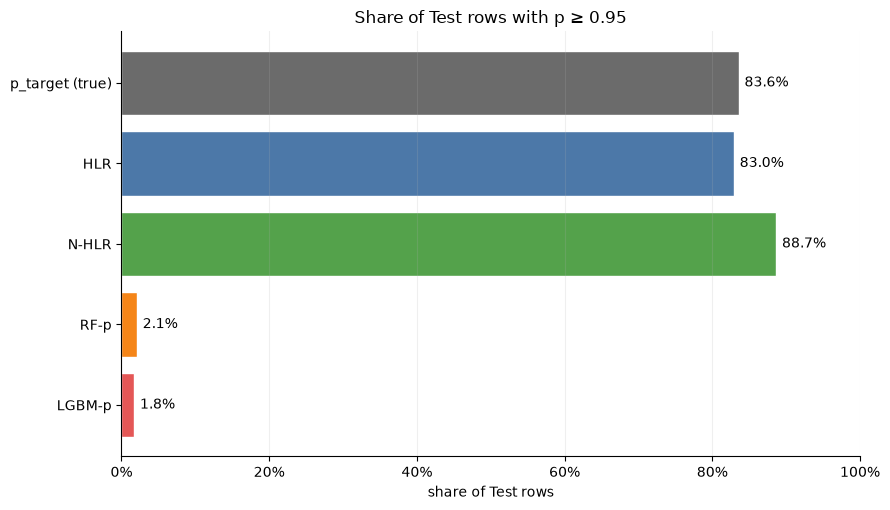

,share_ge_0.95
series,
p_target (true),0.836041
HLR,0.829599
N-HLR,0.886834
RF-p,0.021230
LGBM-p,0.017517


Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_high_prediction_share.png


In [4]:
high_share = (
    distribution_summary.set_index('series')
    .loc[list(distribution_series), 'share_ge_0.95']
)
high_share_colors = ['#6B6B6B', '#4C78A8', '#54A24B', '#F58518', '#E45756']

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(
    high_share.index, high_share.to_numpy(),
    color=high_share_colors, edgecolor='white',
)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{value:.1%}' for value in high_share], padding=4)
ax.set(
    title='Share of Test rows with p ≥ 0.95',
    xlabel='share of Test rows', xlim=(0, 1),
)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.grid(axis='x', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(HIGH_SHARE_PATH, dpi=180, bbox_inches='tight')
plt.show()
display(high_share.rename('share_ge_0.95').to_frame().round(6))
print(f'Saved: {HIGH_SHARE_PATH.resolve()}')


## 9.4 读图结论

Test 标签高度集中在回忆率上界。HLR 和 N-HLR 的预测也集中在接近 1 的区域，因此在占 Test 大多数的高回忆率记录上容易获得较低绝对误差。RF-p 和 LGBM-p 的输出则主要集中在较低且更窄的高概率区间，很少给出 `p ≥ 0.95` 的预测，可以称为相对保守。

这里的“保守”只描述预测分布的位置，不等价于整体模型更好或更差。HLR 系模型的高位集中有利于当前数据分布下的 MAE；直接预测回忆率的树模型虽然 MAE 更高，却在 RMSE 和 AUC 上表现更好。模型比较仍需结合逐行误差和其他指标，不能只根据边际分布得出结论。


## 9.5 为什么 MAE 和 RMSE 给出不同的模型排序？

HLR 的 MAE 低于 RF-p，但 RMSE 更高。为了定位排名反转来自哪些记录，下面按照真实 `p_target` 分组，并把每一组对总体 MAE 和总体 MSE 的贡献相加。

对组 $g$，定义

$$C_{\mathrm{MAE},g}=\frac{N_g}{N}\operatorname{MAE}_g,$$

$$C_{\mathrm{MSE},g}=\frac{N_g}{N}\operatorname{MSE}_g.$$

所有 $C_{\mathrm{MAE},g}$ 相加等于总体 MAE；所有 $C_{\mathrm{MSE},g}$ 相加等于总体 MSE，最后对总体 MSE 开平方才得到 RMSE。**RMSE 本身不能按组直接相加**，因此右图展示的是 MSE contribution，并在整根柱末端标出对应 RMSE。


,model,group,n_group,share,MAE_g,MSE_g,C_MAE,C_MSE
0,HLR,p = MIN_P,90279,0.070233,0.951658,0.916788,0.066838,0.064389
1,HLR,MIN_P < p ≤ 0.2,13,0.000010,0.785759,0.618302,0.000008,0.000006
2,HLR,0.2 < p ≤ 0.5,48508,0.037737,0.472692,0.232218,0.017838,0.008763
3,HLR,0.5 < p < MAX_P,71970,0.055990,0.244573,0.067469,0.013694,0.003778
4,HLR,p = MAX_P,1074645,0.836030,0.035472,0.009178,0.029656,0.007673
5,RF-p,p = MIN_P,90279,0.070233,0.872254,0.767085,0.061261,0.053875
6,RF-p,MIN_P < p ≤ 0.2,13,0.000010,0.464523,0.249884,0.000005,0.000003
7,RF-p,0.2 < p ≤ 0.5,48508,0.037737,0.393611,0.159442,0.014854,0.006017
8,RF-p,0.5 < p < MAX_P,71970,0.055990,0.158337,0.031007,0.008865,0.001736
9,RF-p,p = MAX_P,1074645,0.836030,0.101935,0.011885,0.085221,0.009936


,model,MAE,sum_C_MAE,MSE,sum_C_MSE,RMSE
0,HLR,0.128033,0.128033,0.084610,0.084610,0.290877
1,RF-p,0.170206,0.170206,0.071567,0.071567,0.267520


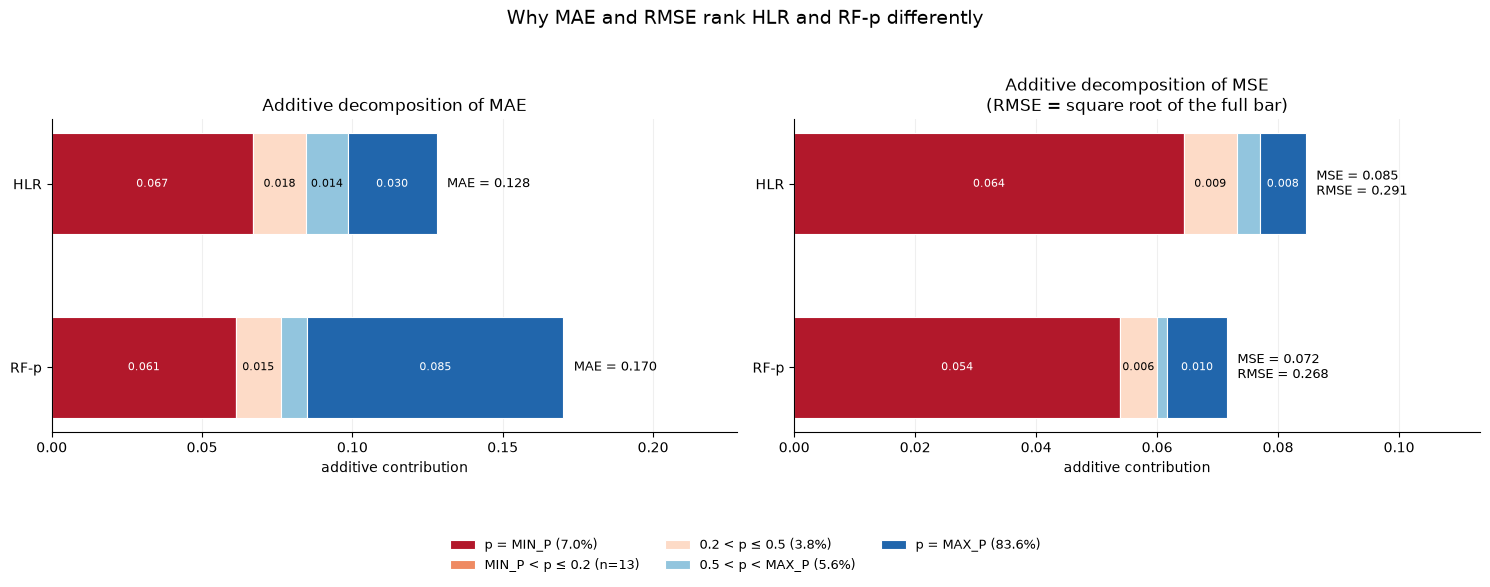

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s09_mae_mse_contribution_stacks.png


In [5]:
DECOMPOSITION_PATH = REPORTS_DIR / 's09_mae_mse_contribution_stacks.png'
decomposition_models = ['HLR', 'RF-p']
decomposition_group_names = [
    'p = MIN_P', 'MIN_P < p ≤ 0.2', '0.2 < p ≤ 0.5',
    '0.5 < p < MAX_P', 'p = MAX_P',
]
true_p = distribution_series['p_target (true)']
decomposition_masks = [
    true_p == MIN_P,
    (true_p > MIN_P) & (true_p <= 0.2),
    (true_p > 0.2) & (true_p <= 0.5),
    (true_p > 0.5) & (true_p < MAX_P),
    true_p == MAX_P,
]
coverage = np.zeros(len(true_p), dtype=np.int8)
for mask in decomposition_masks:
    coverage += mask
assert np.all(coverage == 1), 'p_target groups must cover Test exactly once'

decomposition_rows = []
for model_name in decomposition_models:
    error = distribution_series[model_name] - true_p
    absolute_error = np.abs(error)
    squared_error = error ** 2
    for group_name, mask in zip(decomposition_group_names, decomposition_masks):
        n_group = int(mask.sum())
        decomposition_rows.append({
            'model': model_name,
            'group': group_name,
            'n_group': n_group,
            'share': n_group / len(true_p),
            'MAE_g': float(absolute_error[mask].mean()),
            'MSE_g': float(squared_error[mask].mean()),
            'C_MAE': float(absolute_error[mask].sum() / len(true_p)),
            'C_MSE': float(squared_error[mask].sum() / len(true_p)),
        })

mae_mse_decomposition = pd.DataFrame(decomposition_rows)
decomposition_checks = []
for model_name in decomposition_models:
    part = mae_mse_decomposition[mae_mse_decomposition['model'] == model_name]
    error = distribution_series[model_name] - true_p
    overall_mae = float(np.abs(error).mean())
    overall_mse = float(np.mean(error ** 2))
    assert np.isclose(part['C_MAE'].sum(), overall_mae, rtol=0, atol=1e-12)
    assert np.isclose(part['C_MSE'].sum(), overall_mse, rtol=0, atol=1e-12)
    decomposition_checks.append({
        'model': model_name,
        'MAE': overall_mae,
        'sum_C_MAE': float(part['C_MAE'].sum()),
        'MSE': overall_mse,
        'sum_C_MSE': float(part['C_MSE'].sum()),
        'RMSE': float(np.sqrt(overall_mse)),
    })
decomposition_summary = pd.DataFrame(decomposition_checks)
display(mae_mse_decomposition.round(6))
display(decomposition_summary.round(6))

group_shares = (
    mae_mse_decomposition[mae_mse_decomposition['model'] == decomposition_models[0]]
    .set_index('group')['share']
    .loc[decomposition_group_names]
)
legend_labels = [
    f'{group} ({group_shares[group]:.1%})'
    if group_shares[group] >= 0.001
    else f'{group} (n={int(decomposition_masks[i].sum()):,})'
    for i, group in enumerate(decomposition_group_names)
]
group_colors = ['#B2182B', '#EF8A62', '#FDDBC7', '#92C5DE', '#2166AC']
model_positions = np.arange(len(decomposition_models))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, metric, title in zip(
    axes,
    ['C_MAE', 'C_MSE'],
    ['Additive decomposition of MAE',
     'Additive decomposition of MSE\n(RMSE = square root of the full bar)'],
):
    left = np.zeros(len(decomposition_models), dtype=np.float64)
    for group_name, legend_label, color in zip(
        decomposition_group_names, legend_labels, group_colors
    ):
        values = np.array([
            mae_mse_decomposition.loc[
                (mae_mse_decomposition['model'] == model_name)
                & (mae_mse_decomposition['group'] == group_name), metric
            ].iloc[0]
            for model_name in decomposition_models
        ])
        bars = ax.barh(
            model_positions, values, left=left, height=0.55,
            color=color, edgecolor='white', linewidth=0.8, label=legend_label,
        )
        threshold = 0.06 * max(
            decomposition_summary['MAE' if metric == 'C_MAE' else 'MSE']
        )
        for bar, value in zip(bars, values):
            if value >= threshold:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if color in ('#B2182B', '#2166AC') else 'black',
                )
        left += values
    totals = decomposition_summary.set_index('model').loc[
        decomposition_models, 'MAE' if metric == 'C_MAE' else 'MSE'
    ].to_numpy()
    rmse_values = decomposition_summary.set_index('model').loc[
        decomposition_models, 'RMSE'
    ].to_numpy()
    x_limit = float(totals.max() * 1.34)
    for y, total, rmse in zip(model_positions, totals, rmse_values):
        label = (
            f'MAE = {total:.3f}'
            if metric == 'C_MAE'
            else f'MSE = {total:.3f}\nRMSE = {rmse:.3f}'
        )
        ax.text(total + 0.015 * x_limit, y, label, va='center', fontsize=9)
    ax.set(
        title=title, yticks=model_positions, yticklabels=decomposition_models,
        xlabel='additive contribution', xlim=(0, x_limit),
    )
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc='lower center', ncol=3, frameon=False,
    bbox_to_anchor=(0.5, -0.01), fontsize=9,
)
fig.suptitle('Why MAE and RMSE rank HLR and RF-p differently', fontsize=14)
fig.tight_layout(rect=(0, 0.15, 1, 0.95))
fig.savefig(DECOMPOSITION_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {DECOMPOSITION_PATH.resolve()}')


## 9.6 结论：高频小误差与低频大误差

`p_target=MAX_P` 的记录占 Test 的 83.603%。在这组数量最多的高回忆率记录上，HLR 的 MAE 很低，因此该组对 HLR 总体 MAE 的贡献只有 0.029656，而对 RF-p 的贡献为 0.085221。这一大样本组使 HLR 获得更低的总体 MAE。

另一方面，`p_target=MIN_P` 的记录占 Test 的 7.023%。HLR 会对其中一部分记录给出非常高的预测，因此产生较大的尾部误差；误差平方后，该组对 HLR 总体 MSE 的贡献达到 0.064389，高于 RF-p 的 0.053875。少量大误差在 MSE 中受到更强惩罚，最终使 HLR 的 RMSE 高于 RF-p。

因此，两个指标的排序并不矛盾：**MAE 更受数量占绝对多数的高回忆率记录影响，RMSE 则更敏感于低回忆率记录上的少量大误差。** HLR 的预测分布与标签的高位集中更接近，所以 MAE 较低；RF-p 的预测更保守，减少了灾难性高估，所以 RMSE 较低。右图展示的是可加的 MSE contribution，而不是可直接相加的 RMSE contribution。
